### Executive Summary

#### 1. Data Exploration Key Findings
* **Target Variable (`downgraded_status`):** The dataset is imbalanced, with approximately **13.2%** of clients having downgraded their status.
* **Industry Distribution:** The clients are relatively evenly distributed across five industries: Energy, Finance, Public Sector, Healthcare, and Retail.
* **Complaints as a Strong Predictor:** Exploratory analysis revealed an extremely strong correlation (**0.91**) between `total_q3_complaints` and `downgraded_status`. Clients who downgraded typically experienced significantly more complaints (nearly all had more than 10 complaints in Q3, averaging around 23), whereas active clients had very few (mostly under 8).
* **Missing Values:** The `last_system_login_days` column has **13.2% missing values**, which matches the exact percentage of downgraded accounts. This suggests a potential structural relationship (e.g., login inactivity is only tracked or defined differently for active users, or missing logins are indicative of downgraded status).

#### 2. Model Development Summary
Three modeling approaches were evaluated on the dataset (split into 80% train / 20% test):

* **Baseline Model (Dummy Classifier):** Predicts the majority class (active status). It achieved an accuracy of **87.00%** but registered **0.00% recall** and **precision**, failing to identify any downgrades.
* **Heuristic Complaints-Based Model:** A simple threshold rule (`total_q3_complaints > 10`) yielded a perfect **100% Accuracy, Recall, and Precision** on the test set.
* **Logistic Regression:** Trained on `monthly_spend_usd`, `total_q3_complaints`, and `industry` (one-hot encoded and standardized). This model achieved **100% test performance** and a mean cross-validation accuracy of **99.88%** on the training set.
* **Feature Coefficients:** Confirming the exploratory data analysis, `total_q3_complaints` has by far the largest positive coefficient (~4.76), dominating the model predictions. Industry and monthly spend have negligible influence on the likelihood of downgrading.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
df = pd.read_csv("./client_churn_history.csv")

## Inspect Data

In [3]:
df.head()

,client_id,industry,monthly_spend_usd,total_q3_complaints,last_system_login_days,downgraded_status
0,C-0001,Finance,17531.44,25,NaN,1
1,C-0002,Healthcare,8631.05,19,NaN,1
2,C-0003,Finance,11285.46,2,5.0,0
3,C-0004,Finance,7890.17,5,2.0,0
4,C-0005,Finance,4195.32,2,10.0,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   client_id               1000 non-null   object 
 1   industry                1000 non-null   object 
 2   monthly_spend_usd       1000 non-null   float64
 3   total_q3_complaints     1000 non-null   int64  
 4   last_system_login_days  868 non-null    float64
 5   downgraded_status       1000 non-null   int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 47.0+ KB


In [5]:
(df.isna().sum()/len(df)).sort_values(ascending=False)

,0
last_system_login_days,0.132
client_id,0.000
industry,0.000
monthly_spend_usd,0.000
total_q3_complaints,0.000
downgraded_status,0.000


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.duplicated(subset="client_id").sum()

np.int64(0)

In [8]:

df.describe()

,monthly_spend_usd,total_q3_complaints,last_system_login_days,downgraded_status
count,1000.000000,1000.000000,868.00000,1000.00000
mean,13558.127520,6.466000,7.43894,0.13200
std,6615.603933,6.987393,4.04755,0.33866
min,2010.820000,0.000000,1.00000,0.00000
25%,7935.790000,2.000000,4.00000,0.00000
50%,13382.825000,5.000000,7.00000,0.00000
75%,19241.567500,7.000000,11.00000,0.00000
max,24996.720000,30.000000,14.00000,1.00000


## EDA

### Industry

In [10]:
df["industry"].nunique()

5

In [11]:
df["industry"].unique()

array(['Finance', 'Healthcare', 'Public Sector', 'Energy', 'Retail'],
      dtype=object)

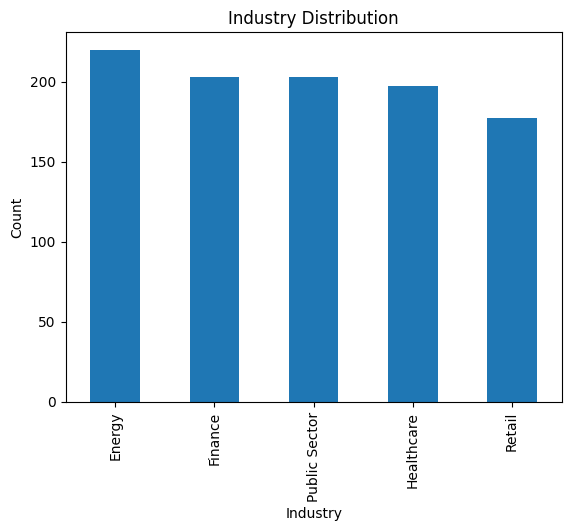

In [12]:
df["industry"].value_counts().plot(kind="bar")
plt.title("Industry Distribution")
plt.xlabel("Industry")
plt.ylabel("Count");

### Monthly Spend

<Axes: ylabel='Frequency'>

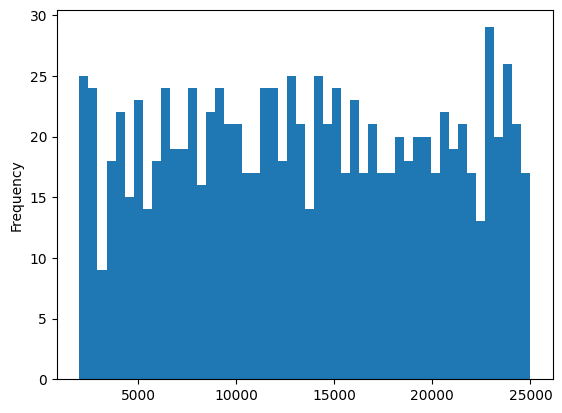

In [13]:
df["monthly_spend_usd"].plot(kind="hist", bins=50)

### Total Q3 Complaints

<Axes: >

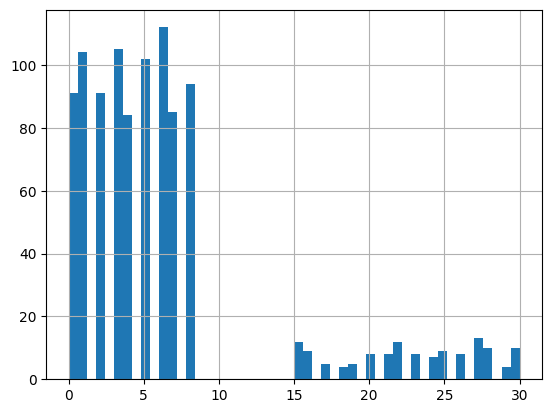

In [14]:
df["total_q3_complaints"].hist(bins=50)

### Last system login in days

<Axes: >

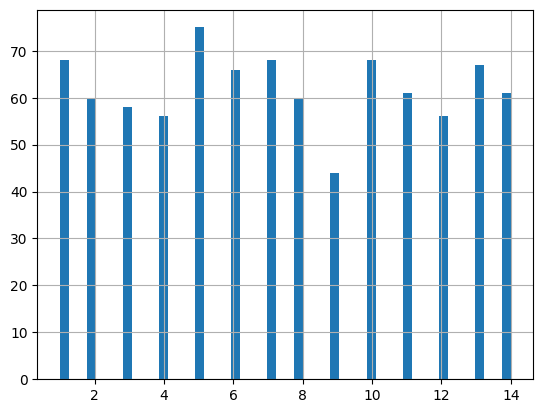

In [15]:
df["last_system_login_days"].hist(bins=50)

### Downgrade status

In [16]:
df["downgraded_status"].value_counts(normalize=True)

,proportion
downgraded_status,
0,0.868
1,0.132


<Axes: xlabel='downgraded_status'>

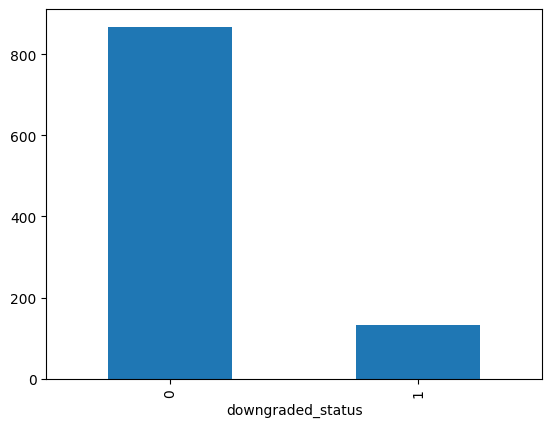

In [17]:
df["downgraded_status"].value_counts().plot(kind="bar")

### Numerical Features vs Target

In [18]:
num_cols = df.select_dtypes(include="number").columns.drop("last_system_login_days")
num_cols

Index(['monthly_spend_usd', 'total_q3_complaints', 'downgraded_status'], dtype='object')

<Axes: >

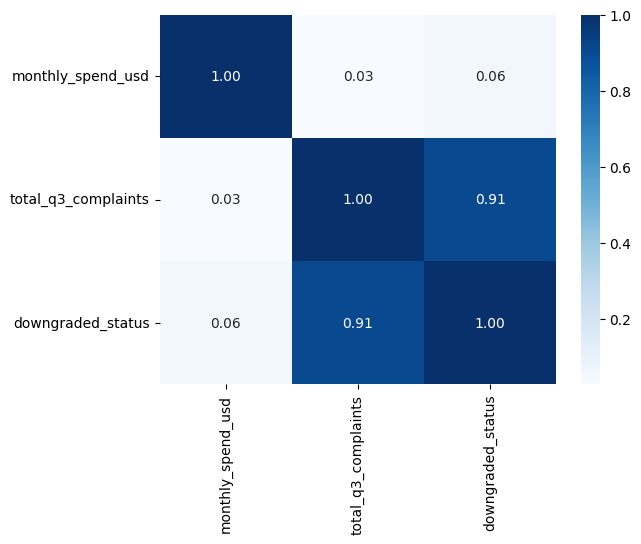

In [19]:
corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues")

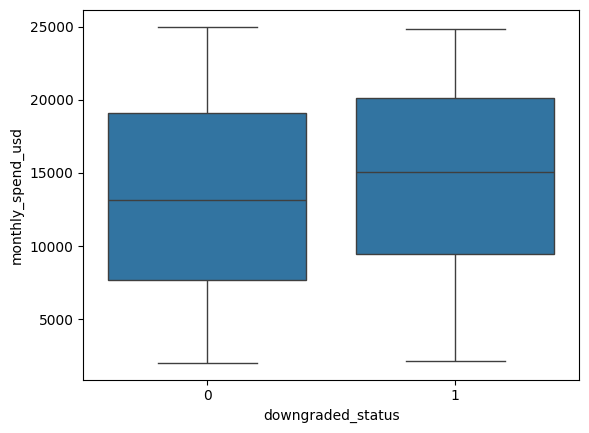

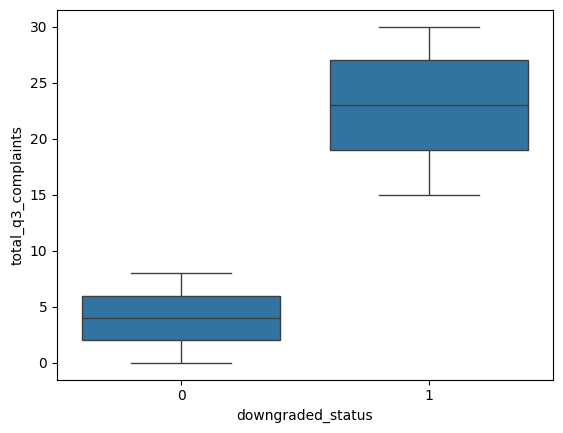

In [20]:
for col in num_cols.drop("downgraded_status"):
    sns.boxplot(x="downgraded_status", y=col, data=df)
    plt.show()

Industry vs Downgraded Status

In [21]:
contingency_table = pd.crosstab(df["industry"], df["downgraded_status"], normalize=True)
contingency_table

downgraded_status,0,1
industry,,
Energy,0.188,0.032
Finance,0.181,0.022
Healthcare,0.165,0.032
Public Sector,0.176,0.027
Retail,0.158,0.019


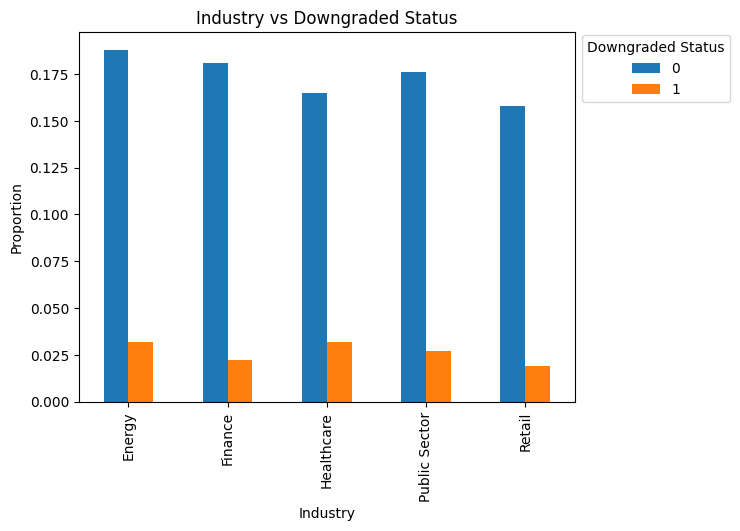

In [22]:
contingency_table.plot(kind="bar")
plt.title("Industry vs Downgraded Status")
plt.xlabel("Industry")
plt.ylabel("Proportion")
plt.legend(bbox_to_anchor=[1, 1.01], title="Downgraded Status");

In [23]:
def wrangle_data(df):
    df = df.copy()
    df["industry"] = df["industry"].str.lower()
    return df

## Modelling

In [44]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn import set_config

In [ ]:
set_config(transform_output="pandas")

In [24]:
data = wrangle_data(df)

### Train-Test Split

In [27]:
num_features = ["monthly_spend_usd", "total_q3_complaints"]
cat_features = ["industry"]

X = data[num_features + cat_features]
y = data["downgraded_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]} samples")
print(f"Test size: {X_test.shape[0]} samples")

Train size: 800 samples
Test size: 200 samples


## Preprocessing

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

## Baseline Model

In [34]:
dummy_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])
dummy_clf.fit(X_train, y_train)
y_pred_dummy = dummy_clf.predict(X_test)

print("Dummy Classifier Metrics (Test Set):")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_dummy, zero_division=0):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dummy, zero_division=0):.4f}")

Dummy Classifier Metrics (Test Set):
Accuracy:  0.8700
Recall:    0.0000
Precision: 0.0000


## Complaints Model

In [38]:
dummy_clf_2_test_pred = X_test["total_q3_complaints"].gt(10).astype(int)

print("Complaints Classifier Metrics (Test Set):")
print(f"Accuracy:  {accuracy_score(y_test, dummy_clf_2_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, dummy_clf_2_test_pred, zero_division=0):.4f}")
print(f"Precision: {precision_score(y_test, dummy_clf_2_test_pred, zero_division=0):.4f}")

Complaints Classifier Metrics (Test Set):
Accuracy:  1.0000
Recall:    1.0000
Precision: 1.0000


## Logistic Regression

In [45]:
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])
log_reg_pipeline.fit(X_train, y_train)
y_pred_lr = log_reg_pipeline.predict(X_test)

print("Logistic Regression Metrics (Test Set):")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")

Logistic Regression Metrics (Test Set):
Accuracy:  1.0000
Recall:    1.0000
Precision: 1.0000


## Cross Validate model

In [46]:
scoring_metrics = ["accuracy", "recall", "precision"]
splitter = StratifiedKFold(n_splits=5)
cv_splits = splitter.split(X_train, y_train)

cv_results = cross_validate(
    log_reg_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring=scoring_metrics,
    return_train_score=False
)

print("5-Fold Cross-Validation Metrics on Training Set:")
print(f"Mean Accuracy:  {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std() * 2:.4f})")
print(f"Mean Recall:    {cv_results['test_recall'].mean():.4f} (+/- {cv_results['test_recall'].std() * 2:.4f})")
print(f"Mean Precision: {cv_results['test_precision'].mean():.4f} (+/- {cv_results['test_precision'].std() * 2:.4f})")

5-Fold Cross-Validation Metrics on Training Set:
Mean Accuracy:  0.9988 (+/- 0.0050)
Mean Recall:    0.9905 (+/- 0.0381)
Mean Precision: 1.0000 (+/- 0.0000)


## Model Inspection

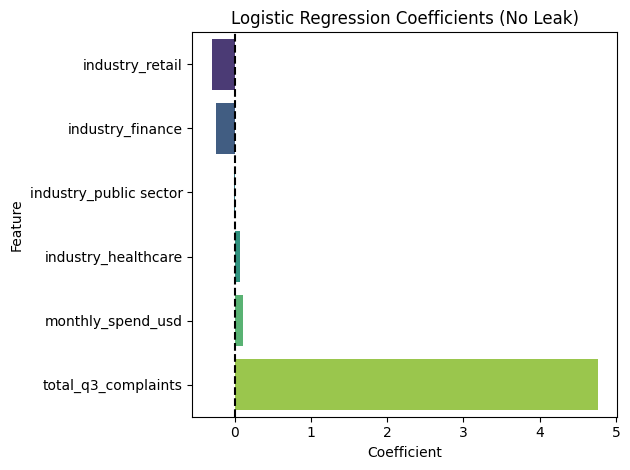

In [49]:
classifier = log_reg_pipeline.named_steps['classifier']
preprocessor_transformer = log_reg_pipeline.named_steps['preprocessor']

feature_names = preprocessor_transformer.get_feature_names_out()
coefficients = classifier.coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=True)

sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='viridis', hue='Feature', legend=False)
plt.title("Logistic Regression Coefficients (No Leak)")
plt.axvline(0, color='black', linestyle='--')

plt.tight_layout()
plt.show()